# code_190 · Partial labels need task-specific evidence

**Book:** section 36.3. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_36_GUIDE.md), [execution evidence](../CHAPTER_36_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_190).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evaluation contracts identify the population, sampling unit, available information, score direction and decision consequences. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7790;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7790


<a id="censor-aware-discrimination"></a>
 ## Keep censored durations out of ordinary regression scores
 Generate 700 source and 500 independent final lifetimes with exponential rate 0.15 exp(0.7x). Fit an actual one-coefficient Cox partial likelihood on source observations censored independently Uniform(0,10); compute its Breslow baseline. The same final lifetimes are then observed under two independent censoring mechanisms, Uniform(0,10) and Uniform(0,6). Report comparable-pair concordance and an IPC-weighted, age-five-truncated concordance, plus age-four survival Brier with IPC weights. This controlled experiment uses the known censor survival G(t)=1−t/c, not an estimated nuisance model, and explicitly labels the latent-lifetime concordance as simulator-only audit. No claim of censor-robustness under dependent censoring follows.


,event_fraction,raw_C_tau5,IPCW_C_tau5,comparable_pairs,IPCW_Brier_age4,latent_Brier_age4_audit
10,0.512,0.674885,0.673481,72925.0,0.225059,0.21508
6,0.356,0.682503,0.675049,55821.0,0.196468,0.21508


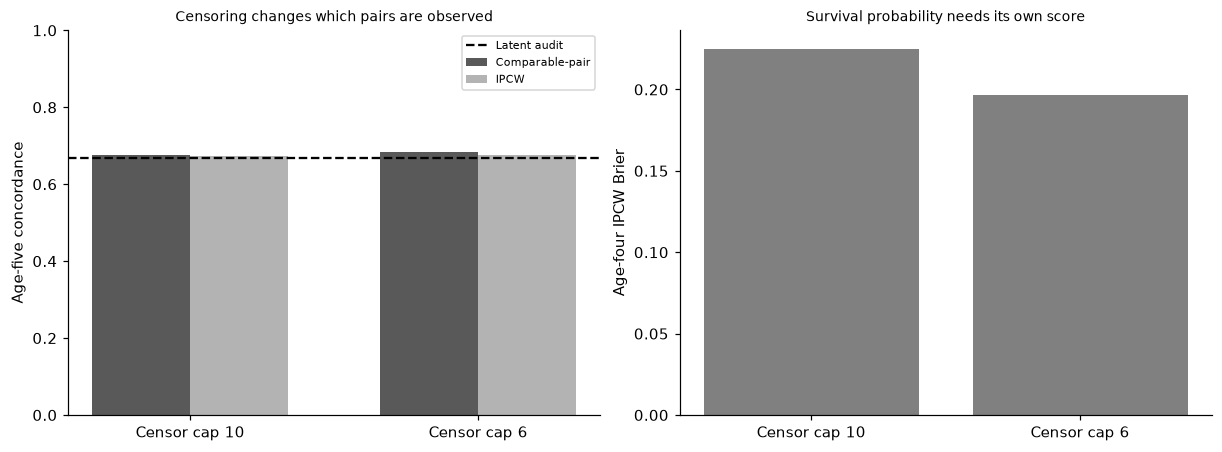

In [2]:
from scipy.optimize import minimize
from scipy.special import logsumexp
xs=rng.normal(size=700);ts=rng.exponential(1/(.15*np.exp(.7*xs)));cs=rng.uniform(0,10,700);obs=np.minimum(ts,cs);event=ts<=cs
def nll(b):
    z=b[0]*xs;return -sum(z[i]-logsumexp(z[obs>=obs[i]]) for i in np.flatnonzero(event))+.001*b[0]**2
fit=minimize(nll,[0.],method='BFGS',options={'gtol':1e-5});beta=float(fit.x[0]);assert fit.success;times=np.unique(obs[event]);increments=np.array([np.sum(event&(obs==t))/np.exp(beta*xs[obs>=t]).sum() for t in times]);h4=float(increments[times<=4].sum());xf=rng.normal(size=500);tf=rng.exponential(1/(.15*np.exp(.7*xf)));risk=beta*xf;survival=np.exp(-h4*np.exp(risk))
def concordance(t,d,r,w=None,tau=np.inf):
    a=(t[:,None]<t[None,:])&d[:,None]&(t[:,None]<=tau);s=(r[:,None]>r[None,:])+.5*(r[:,None]==r[None,:]);weights=np.ones(len(t)) if w is None else w;return float(np.sum(a*s*weights[:,None])/np.sum(a*weights[:,None])),int(a.sum())
audit,_=concordance(tf,np.ones(500,dtype=bool),risk,tau=5);surv={}
for cap in [10,6]:
    cf=rng.uniform(0,cap,500);t=np.minimum(tf,cf);d=tf<=cf;g=lambda z:np.maximum(1-z/cap,1e-12);raw,pairs=concordance(t,d,risk,tau=5);weighted,_=concordance(t,d,risk,1/g(t)**2,tau=5);wb=((t<=4)&d)*(survival**2)/g(t)+(t>4)*((1-survival)**2)/g(4);surv[str(cap)]={'event_fraction':float(d.mean()),'raw_C_tau5':raw,'IPCW_C_tau5':weighted,'comparable_pairs':pairs,'IPCW_Brier_age4':float(wb.mean()),'latent_Brier_age4_audit':float(np.mean(((tf>4)-survival)**2))};assert np.isfinite(wb).all() and pairs>0
RESULTS.update(Cox_beta=beta,optimizer_success=bool(fit.success),source_records=700,final_records=500,censoring_mechanism='known independent Uniform(0,cap)',survival_scores=surv,latent_C_tau5_audit=audit);display(pd.DataFrame(surv).T)
fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(2);axes[0].bar(xx-.17,[surv[str(c)]['raw_C_tau5'] for c in [10,6]],width=.34,color='.35',label='Comparable-pair');axes[0].bar(xx+.17,[surv[str(c)]['IPCW_C_tau5'] for c in [10,6]],width=.34,color='.7',label='IPCW');axes[0].axhline(audit,color='black',linestyle='--',label='Latent audit');axes[0].set(xticks=xx,xticklabels=['Censor cap 10','Censor cap 6'],ylim=(0,1),ylabel='Age-five concordance',title='Censoring changes which pairs are observed');axes[0].legend(fontsize=7);axes[1].bar(xx,[surv[str(c)]['IPCW_Brier_age4'] for c in [10,6]],color='.5');axes[1].set(xticks=xx,xticklabels=['Censor cap 10','Censor cap 6'],ylabel='Age-four IPCW Brier',title='Survival probability needs its own score');plt.show()


<a id="cluster-stability-and-agreement"></a>
 ## Separate reproducibility of a partition from its scientific meaning
 Generate 600 source and 200 independent anchor records from three known anisotropic regimes. For candidate cluster counts 2, 3 and 5, fit twenty native KMeans partitions to bootstrap samples of source records. Assess agreement between their predictions on the common anchor records using adjusted Rand index; compare the first fixed fit with latent anchor regimes and its geometric silhouette. Stability, external agreement and geometry have different targets. Latent regimes are an audit privilege of this generator and are not an available label set for ordinary unsupervised deployment. Candidate counts remain parallel descriptive comparisons, never chosen from the anchor audit.


,mean_pairwise_stability_ARI,minimum_pairwise_stability_ARI,external_latent_ARI,silhouette
2,0.889605,0.654366,0.500282,0.608208
3,0.851280,0.610590,0.552461,0.524769
5,0.702182,0.407407,0.381880,0.480845


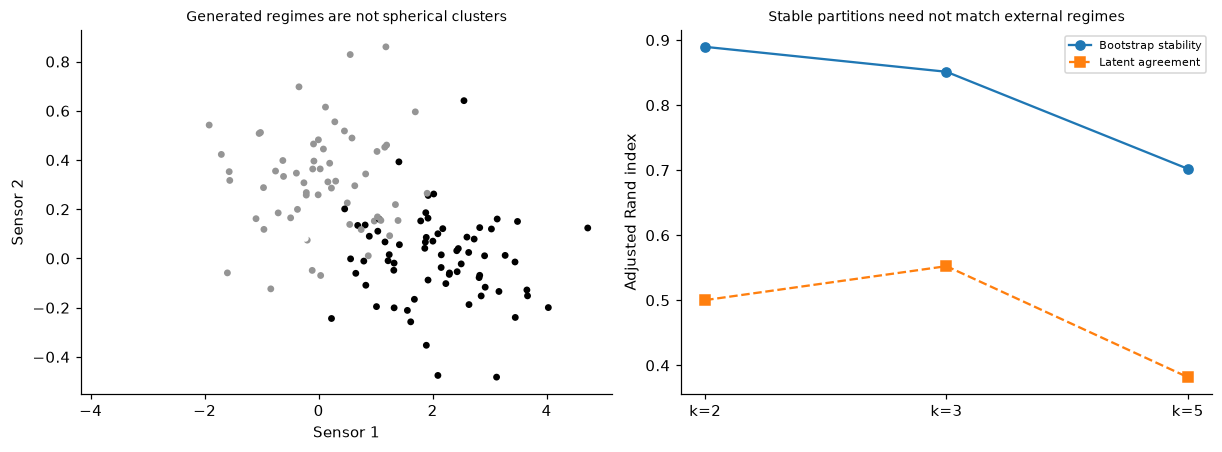

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score,silhouette_score
def cluster_data(n):
    label=rng.integers(0,3,n);centres=np.array([[-2,0],[0,.3],[2,0]]);x=centres[label]+rng.normal(size=(n,2))*np.array([.9,.18]);return x,label
zsource,_=cluster_data(600);anchor,latent=cluster_data(200);cluster_rows={}
for k in [2,3,5]:
    predictions=[KMeans(n_clusters=k,n_init=5,random_state=SEED+j).fit(zsource[rng.integers(0,600,600)]).predict(anchor) for j in range(20)];agreement=[adjusted_rand_score(predictions[i],predictions[j]) for i in range(20) for j in range(i+1,20)];cluster_rows[str(k)]={'mean_pairwise_stability_ARI':float(np.mean(agreement)),'minimum_pairwise_stability_ARI':float(np.min(agreement)),'external_latent_ARI':float(adjusted_rand_score(latent,predictions[0])),'silhouette':float(silhouette_score(anchor,predictions[0]))};assert len(agreement)==190 and all(len(np.unique(p))==k for p in predictions)
assert adjusted_rand_score(latent,latent)==1;RESULTS.update(cluster_source=600,cluster_anchor=200,bootstrap_partitions_per_k=20,clustering_scores=cluster_rows);display(pd.DataFrame(cluster_rows).T);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].scatter(anchor[:,0],anchor[:,1],c=latent,cmap='Greys',s=12);axes[0].set(xlabel='Sensor 1',ylabel='Sensor 2',title='Generated regimes are not spherical clusters');xx=np.arange(3);axes[1].plot(xx,[cluster_rows[str(k)]['mean_pairwise_stability_ARI'] for k in [2,3,5]],'o-',label='Bootstrap stability');axes[1].plot(xx,[cluster_rows[str(k)]['external_latent_ARI'] for k in [2,3,5]],'s--',label='Latent agreement');axes[1].set(xticks=xx,xticklabels=['k=2','k=3','k=5'],ylabel='Adjusted Rand index',title='Stable partitions need not match external regimes');axes[1].legend(fontsize=7);plt.show()


<a id="alarm-episodes-and-point-adjustment"></a>
 ## Count events, lead times and operating burden explicitly
 Six assets operate 180 days each. Each has three fixed, nonoverlapping generated fault intervals; a warning is useful from three days before fault onset through its last fault day. Compare two declared score fixtures, a precursor-sensitive noisy monitor and independent random alarms at probability 0.06; these are evaluation stress controls, not fitted anomaly detectors. Point F1 uses only fault days as positives. Event recall counts at least one alarm in the warning/event window; lead time is onset minus earliest qualifying alarm, conditional on detection. False-alarm episodes are contiguous alarm runs whose first day lies outside every warning/event window; report episodes per 30 asset-days. Point adjustment labels every fault day positive after any within-fault alarm; show that score separately as an inflated retrospective diagnostic, never as the deployed prediction.


,point_F1,point_adjusted_F1_diagnostic,detected_events,total_events,event_recall,median_detected_lead_days,false_alarm_episodes,false_episodes_per30_asset_days
Monitor,0.743421,0.899135,18.0,18.0,1.000000,2.0,9.0,0.250000
Random,0.072727,0.452555,7.0,18.0,0.388889,-1.0,50.0,1.388889


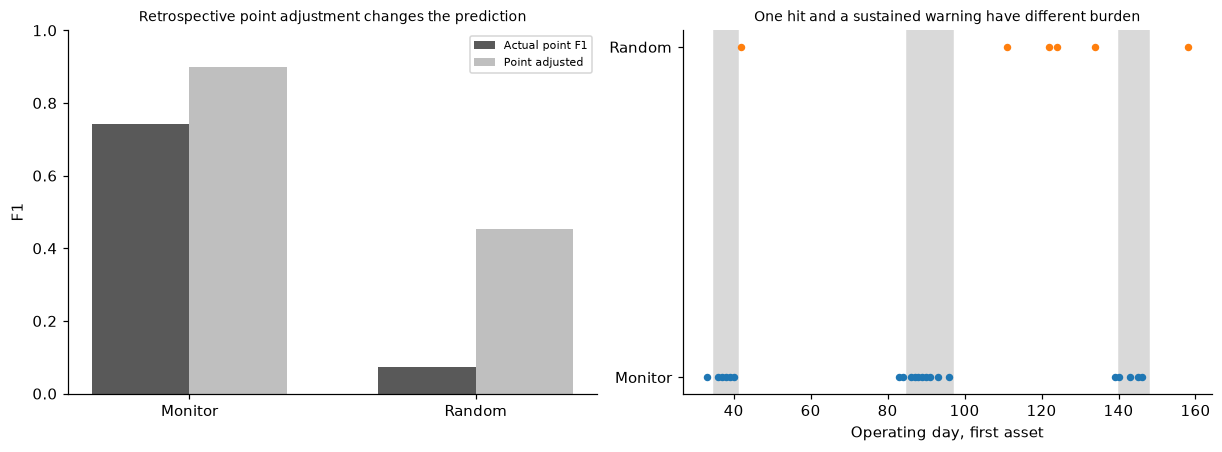

In [4]:
from sklearn.metrics import f1_score
assets=6;days=180;fault=np.zeros((assets,days),bool);window=fault.copy();events=[];precursor=np.zeros_like(fault,dtype=float)
for a in range(assets):
    for onset,duration in [(35+a,6),(85+a,12),(140+a,8)]:
        stop=onset+duration;fault[a,onset:stop]=True;window[a,onset-3:stop]=True;precursor[a,onset-2:stop]=2.7;events.append((a,onset,stop))
alarms={'Monitor':precursor+rng.normal(size=fault.shape)>2.2,'Random':rng.random(fault.shape)<.06};alarm_rows={}
for name,p in alarms.items():
    adjusted=p.copy();lead=[];hits=0
    for a,start,stop in events:
        ids=np.flatnonzero(p[a,start-3:stop])+start-3
        if len(ids):hits+=1;lead.append(start-int(ids[0]))
        if p[a,start:stop].any():adjusted[a,start:stop]=True
    starts=p&~np.c_[np.zeros(assets,bool),p[:,:-1]];false=int(np.sum(starts&~window));alarm_rows[name]={'point_F1':float(f1_score(fault.ravel(),p.ravel())),'point_adjusted_F1_diagnostic':float(f1_score(fault.ravel(),adjusted.ravel())),'detected_events':hits,'total_events':18,'event_recall':hits/18,'median_detected_lead_days':float(np.median(lead)),'false_alarm_episodes':false,'false_episodes_per30_asset_days':false/(assets*days/30)};assert np.all(adjusted>=p)
assert len(events)==18 and assets*days==1080;RESULTS.update(alarm_scores=alarm_rows,operating_asset_days=1080,warning_days_before_onset=3,false_episode_definition='alarm-run start outside any warning/event window');display(pd.DataFrame(alarm_rows).T);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(2);names=list(alarms);axes[0].bar(xx-.17,[alarm_rows[k]['point_F1'] for k in names],width=.34,color='.35',label='Actual point F1');axes[0].bar(xx+.17,[alarm_rows[k]['point_adjusted_F1_diagnostic'] for k in names],width=.34,color='.75',label='Point adjusted');axes[0].set(xticks=xx,xticklabels=names,ylim=(0,1),ylabel='F1',title='Retrospective point adjustment changes the prediction');axes[0].legend(fontsize=7)
for a,start,stop in events:
    if a==0:axes[1].axvspan(start,stop,color='.85')
for j,name in enumerate(names):axes[1].scatter(np.flatnonzero(alarms[name][0]),np.full(alarms[name][0].sum(),j),s=15,label=name)
axes[1].set(yticks=[0,1],yticklabels=names,xlabel='Operating day, first asset',title='One hit and a sustained warning have different burden');plt.show()


In [5]:
summary={'example_id':'code_190','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual source Cox likelihood and censor-aware discrimination and Brier scores', 'bootstrap-fitted KMeans stability separated from external agreement', 'pointwise eventwise warning time and false alarm episode denominators', 'explicit demonstration of point adjustment inflation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual source Cox likelihood and censor-aware discrimination and Brier scores", "bootstrap-fitted KMeans stability separated from external agreement", "pointwise eventwise warning time and false alarm episode denominators", "explicit demonstration of point adjustment inflation"], "elapsed_seconds": 0.827, "example_id": "code_190", "hardware": "Darwin arm64 CPU", "results": {"Cox_beta": 0.6325064812443139, "alarm_scores": {"Monitor": {"detected_events": 18, "event_recall": 1.0, "false_alarm_episodes": 9, "false_episodes_per30_asset_days": 0.25, "median_detected_lead_days": 2.0, "point_F1": 0.743421052631579, "point_adjusted_F1_diagnostic": 0.899135446685879, "total_events": 18}, "Random": {"detected_events": 7, "event_recall": 0.3888888888888889, "false_alarm_episodes": 50, "false_episodes_per30_asset_days": 1.3888888888888888, "median_detected_lead_days": -1.0, "point_F1": 0.07272727272727272, "point_adjusted_F1_diagnostic": 0.45255474